In [27]:
import numpy as np
import pandas as pd
import akshare as ak
import time
import os
from pathlib import Path
import follow_the_leader
from matplotlib import pyplot as plt

## 数据获取

In [2]:
### 获取所有概念代码
# board_concept_codes = ak.stock_board_concept_name_em()  # 东方财富-概念板块；网络不稳定，几乎获取不到数据
board_concept_codes = ak.stock_zh_index_spot_sina()  # 实时行情数据-新浪；其中会返回所有指数的实时行情数据，这里我们更关注指数的代码
board_concept_codes.to_excel("指数代码.xlsx",index=False)  # 使用 Akshare 库时养成随手保存数据的好习惯
board_concept_codes

  0%|          | 0/8 [00:00<?, ?it/s]

,代码,名称,最新价,涨跌额,涨跌幅,昨收,今开,最高,最低,成交量,成交额
0,sh000001,上证指数,3813.7913,1.887,0.050,3811.9043,3804.0896,3824.7091,3754.1353,535149921,888561198264
1,sh000002,Ａ股指数,3998.4528,1.939,0.049,3996.5135,3988.3020,4009.9219,3935.8470,534833738,888164326841
2,sh000003,Ｂ股指数,310.6763,1.486,0.481,309.1902,309.4626,310.7881,307.6790,243828,130092985
3,sh000004,工业指数,3509.7655,1.987,0.057,3507.7783,3493.8788,3520.6803,3425.6688,334811770,706227750728
4,sh000005,商业指数,2604.0585,12.990,0.501,2591.0685,2592.8426,2612.1056,2580.2637,39999504,38664526758
...,...,...,...,...,...,...,...,...,...,...,...
557,sz980030,消费电子,7724.5540,-102.782,-1.313,7827.3360,7742.7820,7771.6480,7418.9440,3008006760,100322322963
558,sz980032,新能电池,12590.4940,207.164,1.673,12383.3300,12366.8850,12634.9520,12237.5350,1717943201,73669588947
559,sz980035,化肥农药,1996.2270,26.779,1.360,1969.4480,1966.4490,2000.2140,1960.7480,1007372956,11468341419
560,sz980076,通用航空,2588.0790,-5.251,-0.202,2593.3300,2588.8210,2602.4710,2515.0290,823163015,16892382046


In [27]:
### 以此获取所有指数的历史行情数据
os.makedirs("history_board_concept_data",exist_ok=True)
folder = Path("history_board_concept_data")
files = [f.name for f in folder.iterdir() if f.is_file()]
for idx in board_concept_codes.index:
    name = board_concept_codes['名称'][idx]
    code = board_concept_codes['代码'][idx]
    excel_name = name+"_"+code
    addre = "./history_board_concept_data/"+excel_name+".xlsx"
    # print(addre)
    if excel_name+".xlsx" in files:  # 跳过由于中断而之前已经保留过的数据
        continue
    data = ak.stock_zh_index_daily(symbol=code)  # 历史行情数据-新浪
    data.to_excel(addre,index=False)
    print(f"已执行：{name}，代码为{code}")
    time.sleep(1)  # 每次循环结束后等待 1 秒，防止触发网页反爬监测

已执行：深主板50，代码为sz399750
已执行：500深市，代码为sz399802
已执行：工业4.0，代码为sz399803
已执行：中证体育，代码为sz399804
已执行：互联金融，代码为sz399805
已执行：环境治理，代码为sz399806
已执行：高铁产业，代码为sz399807
已执行：中证新能，代码为sz399808
已执行：保险主题，代码为sz399809
已执行：CSSW传媒，代码为sz399810
已执行：CSSW电子，代码为sz399811
已执行：养老产业，代码为sz399812
已执行：中证国安，代码为sz399813
已执行：大农业，代码为sz399814
已执行：深证50，代码为sz399850
已执行：中证1000，代码为sz399852
已执行：小康指数，代码为sz399901
已执行：中证100，代码为sz399903
已执行：中证 500，代码为sz399905
已执行：300 医药，代码为sz399913
已执行：300 金融，代码为sz399914
已执行：中证能源，代码为sz399928
已执行：中证消费，代码为sz399932
已执行：中证医药，代码为sz399933
已执行：中证金融，代码为sz399934
已执行：中证信息，代码为sz399935
已执行：军工指数，代码为sz399959
已执行：800地产，代码为sz399965
已执行：800非银，代码为sz399966
已执行：中证军工，代码为sz399967
已执行：移动互联，代码为sz399970
已执行：中证传媒，代码为sz399971
已执行：300深市，代码为sz399972
已执行：中证国防，代码为sz399973
已执行：国企改革，代码为sz399974
已执行：证券公司，代码为sz399975
已执行：CS新能车，代码为sz399976
已执行：500等权，代码为sz399982
已执行：地产等权，代码为sz399983
已执行：中证银行，代码为sz399986
已执行：中证酒，代码为sz399987
已执行：中证医疗，代码为sz399989
已执行：煤炭等权，代码为sz399990
已执行：一带一路，代码为sz399991
已执行：CSWD并购，代码为sz399992
已执行：CSWD生科，代码为sz399993
已执行：信息安全，代码

In [3]:
### 获取美股纳斯达克指数历史行情数据
ixic_hist = ak.index_us_stock_sina(symbol=".IXIC")
ixic_hist.to_excel("纳指历史行情数据.xlsx",index=False)
ixic_hist

,date,open,high,low,close,volume,amount
0,2004-01-02,2011.0800,2022.3700,1999.7700,2006.6801,1666780032,3350190000000
1,2004-01-05,2020.7800,2047.3600,2020.7800,2047.3600,2362909952,4806320000000
2,2004-01-06,2044.5500,2061.5400,2039.6300,2057.3701,2273220096,4661860000000
3,2004-01-07,2056.7500,2078.0901,2047.0200,2077.6799,2294279936,4737420000000
4,2004-01-08,2089.6001,2100.2500,2078.0500,2100.2500,2683950080,5614920000000
...,...,...,...,...,...,...,...
5724,2026-10-05,27225.9297,27544.0645,27223.4941,27477.3105,6811987366,0
5725,2026-10-06,27641.1719,27722.7480,27592.5566,27599.7910,6838364543,0
5726,2026-10-07,27430.5352,27547.2031,27341.3086,27538.6914,6281196183,0
5727,2026-10-08,27416.0312,27491.8945,27066.7578,27193.3398,7641006567,0


## 因子分析

,date,profit
1,2004-01-05,0.020272
2,2004-01-06,0.004889
3,2004-01-07,0.009872
4,2004-01-08,0.010863
5,2004-01-09,-0.006347
...,...,...
5724,2026-10-05,0.010535
5725,2026-10-06,0.004458
5726,2026-10-07,-0.002214
5727,2026-10-08,-0.012541


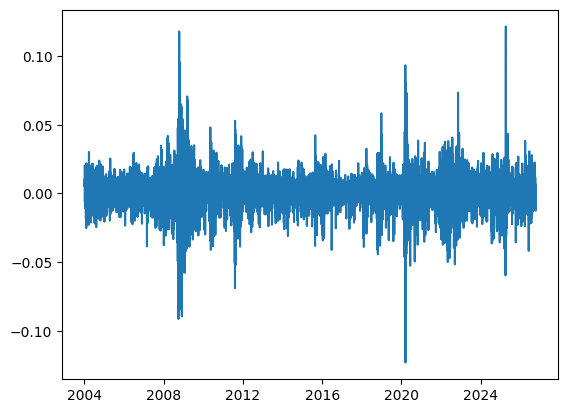

In [31]:
# 计算纳指每日收益
ixic_profit = pd.DataFrame()
ixic_profit['date'] = ixic_hist['date'].iloc[1:]
ixic_profit['profit'] = (np.array(ixic_hist['close'].iloc[1:]) - np.array(ixic_hist['close'].iloc[:-1])) / np.array(ixic_hist['close'].iloc[:-1])
plt.plot(ixic_profit['date'],ixic_profit['profit'])
ixic_profit

In [32]:
# 计算所有A股指数收益
folder = Path("history_board_concept_data")
files = [f.name for f in folder.iterdir() if f.is_file()]


In [33]:
files

['1000价值_sz399631.xlsx',
 '1000信息_sz399388.xlsx',
 '1000公用_sz399390.xlsx',
 '1000医药_sz399386.xlsx',
 '1000可选_sz399384.xlsx',
 '1000地产_sz399367.xlsx',
 '1000工业_sz399383.xlsx',
 '1000成长_sz399630.xlsx',
 '1000材料_sz399382.xlsx',
 '1000消费_sz399385.xlsx',
 '1000能源_sz399381.xlsx',
 '1000金融_sz399387.xlsx',
 '100低波_sz399645.xlsx',
 '100绩效_sz399656.xlsx',
 '180R价值_sh000031.xlsx',
 '180R成长_sh000030.xlsx',
 '180价值_sh000029.xlsx',
 '180低贝_sh000136.xlsx',
 '180分层_sh000093.xlsx',
 '180动态_sh000123.xlsx',
 '180基建_sh000025.xlsx',
 '180基本_sh000053.xlsx',
 '180成长_sh000028.xlsx',
 '180治理_sh000021.xlsx',
 '180波动_sh000129.xlsx',
 '180稳定_sh000125.xlsx',
 '180等权_sh000051.xlsx',
 '180红利_sh000149.xlsx',
 '180资源_sh000026.xlsx',
 '180运输_sh000027.xlsx',
 '180金融_sh000018.xlsx',
 '180高贝_sh000135.xlsx',
 '300 医药_sz399913.xlsx',
 '300 金融_sz399914.xlsx',
 '300医药_sh000913.xlsx',
 '300深市_sz399972.xlsx',
 '300绩效_sz399657.xlsx',
 '300金融_sh000914.xlsx',
 '300非银_sh000849.xlsx',
 '380R价值_sh000120.xlsx',
 '380R成长_sh000119.xlsx'

In [6]:
np.random.seed(0)

T, N = 500, 30
k_true = 5

F_true = np.random.randn(T, k_true)
B_true = np.random.randn(N, k_true)

# 模拟候选工具收益。可把前几个工具设为反向 ETF 的负载荷。
B_true[:3, :] *= -1.0
R = F_true @ B_true.T + 0.5 * np.random.randn(T, N)

# 目标指数收益
b_true = np.random.randn(k_true)
r_target = F_true @ b_true + 0.5 * np.random.randn(T)

# 1) 估计因子数
k_hat, ic2_values = follow_the_leader.estimate_num_factors_ic2(R, kmax=10)
print("估计因子数:", k_hat)

# 2) 估计因子和载荷
F_hat, Lambda_hat = follow_the_leader.pca_factors(R, k_hat)

# 3) Follow-the-Leader 选指数
leaders_per_factor, union = follow_the_leader.follow_the_leader_select(R, F_hat)
print("每个因子的 leader:", leaders_per_factor)
print("并集:", union)

# 4) 目标因子暴露
B_target = np.linalg.lstsq(F_hat, r_target, rcond=None)[0]

# 5) 压到 3 到 5 个
K = 5
if len(union) > K:
    selected = follow_the_leader.greedy_select(Lambda_hat, B_target, K=K)
else:
    selected = union

# 6) 非负权重，合成目标指数的空头因子暴露
w = follow_the_leader.solve_nonneg_weights(Lambda_hat[selected, :], B_target)

print("最终选出的指数索引:", selected)
print("非负权重:", w)
print("组合因子暴露:", Lambda_hat[selected, :].T @ w)
print("目标因子暴露:", B_target)
print("目标相反暴露:", -B_target)

估计因子数: 5
每个因子的 leader: [[1, 6, 7, 8, 9, 10, 12, 13, 14, 15, 17, 19, 20, 21, 22, 23, 24, 25, 26, 28, 29], [0, 1, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 18, 19, 21, 22, 23, 24, 26, 29], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 15, 16, 17, 21, 22, 23, 25, 28], [0, 2, 3, 4, 5, 7, 8, 11, 12, 13, 14, 15, 16, 17, 18, 20, 22, 23, 25, 27, 28], [0, 1, 2, 3, 4, 5, 6, 8, 9, 10, 12, 13, 18, 20, 21, 22, 23, 24, 25, 26, 27]]
并集: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
最终选出的指数索引: [4, 6, 27, 24, 29]
非负权重: [0.75362286 0.10099132 0.10580833 0.02482075 0.01475674]
组合因子暴露: [ 0.31074302 -0.40569987 -0.75259276  0.49109116  0.54355443]
目标因子暴露: [-0.31060427  0.40620706  0.74809591 -0.48856498 -0.54925546]
目标相反暴露: [ 0.31060427 -0.40620706 -0.74809591  0.48856498  0.54925546]
